# **Lab 7: Time Series Analysis**

**Course**: **INS-605: Data Analysis II** <br>
**Lecturer**: **Sothea HAS, PhD**

-----

- Student name: ...
- ID: ...

-----

> The jupyter notebook can be downloaded [here](https://hassothea.github.io/AUPP_Data_Analysis_II/Labs/Lab7/lab7-time-series.ipynb){target="_blank"}.

In [1]:
# These are the libraries that you will need for this lab
import itertools, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 3.5)
SEED = 605

-------

## **1. Simulated Series: Stationarity, ACF & PACF** *(~15 min)*

**Goal:** know what stationary / non-stationary series look like, test it, and read the orders $p,q$ from ACF/PACF. Here the true model is known, so you can check your reading.

### **1.1. Visualization & Stationarity**

Run the cell below to simulate three series ($n=500$):

- $\text{AR}(2)$: $X_t=0.5X_{t-1}+0.3X_{t-2}+\varepsilon_t$
- $\text{MA}(1)$: $X_t=\varepsilon_t+0.8\varepsilon_{t-1}$
- Random walk with drift: $X_t=X_{t-1}+0.1+\varepsilon_t$

In [2]:
rng = np.random.default_rng(SEED)
n = 500
e = rng.normal(size=n + 2)

ar2 = np.zeros(n + 2)
for t in range(2, n + 2):
    ar2[t] = 0.5 * ar2[t-1] + 0.3 * ar2[t-2] + e[t]
ma1 = e[1:] + 0.8 * e[:-1]
rw = np.cumsum(0.1 + e)

idx = pd.date_range('2000-01-01', periods=n, freq='D')
sim = pd.DataFrame({'AR(2)': ar2[2:], 'MA(1)': ma1[1:], 'RandomWalk': rw[2:]}, index=idx)
sim.head()

,AR(2),MA(1),RandomWalk
2000-01-01,-0.501424,-1.623168,-0.486716
2000-01-02,-0.344170,-0.494597,-0.480175
2000-01-03,-1.025096,-0.777351,-1.082759
2000-01-04,-1.394445,-1.340713,-1.761404
2000-01-05,-0.047277,0.334558,-0.703930


**A.** Plot each series with its **rolling mean** and **rolling std** (window = 50). Which series have a constant mean and variance?

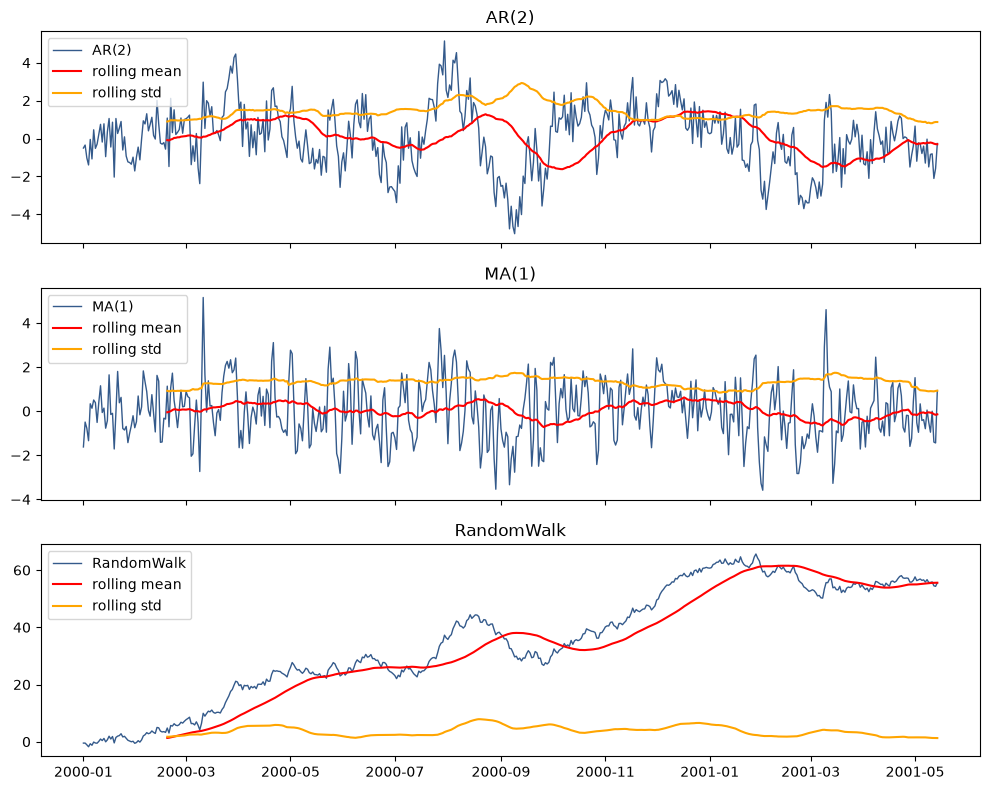

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, col in zip(axes, sim.columns):
    roll_mean = sim[col].rolling(50).mean()   # TODO: sim[col].rolling(50).mean()
    roll_std = sim[col].rolling(50).std()    # TODO: sim[col].rolling(50).std()
    ax.plot(sim[col], color='#345a8b', lw=1, label=col)
    ax.plot(roll_mean, color='red', label='rolling mean')
    ax.plot(roll_std, color='orange', label='rolling std')
    ax.set_title(col); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

**B.** Complete `adf_report` and run the **ADF test** on each series.

- $H_0$: the series is **non-stationary** (unit root) vs. $H_1$: stationary. Reject $H_0$ if p-value $<\alpha=0.05$.

In [22]:
def adf_report(x, name='', alpha=0.05):
    stat, pval, *_ = adfuller(pd.Series(x).dropna(), autolag='AIC')
    return {'series': name, 'ADF stat': stat, 'p-value': pval,
            'stationary?': 'True' if pval < alpha else 'False'}   # TODO: decision at level alpha

pd.DataFrame([adf_report(sim[c], c) for c in sim.columns]).set_index('series').round(4)

,ADF stat,p-value,stationary?
series,,,
AR(2),-3.9371,0.0018,True
MA(1),-4.5616,0.0002,True
RandomWalk,-1.5988,0.4842,False


**C.** Difference the random walk once ($\Delta X_t=X_t-X_{t-1}$), plot it, and rerun the ADF test.

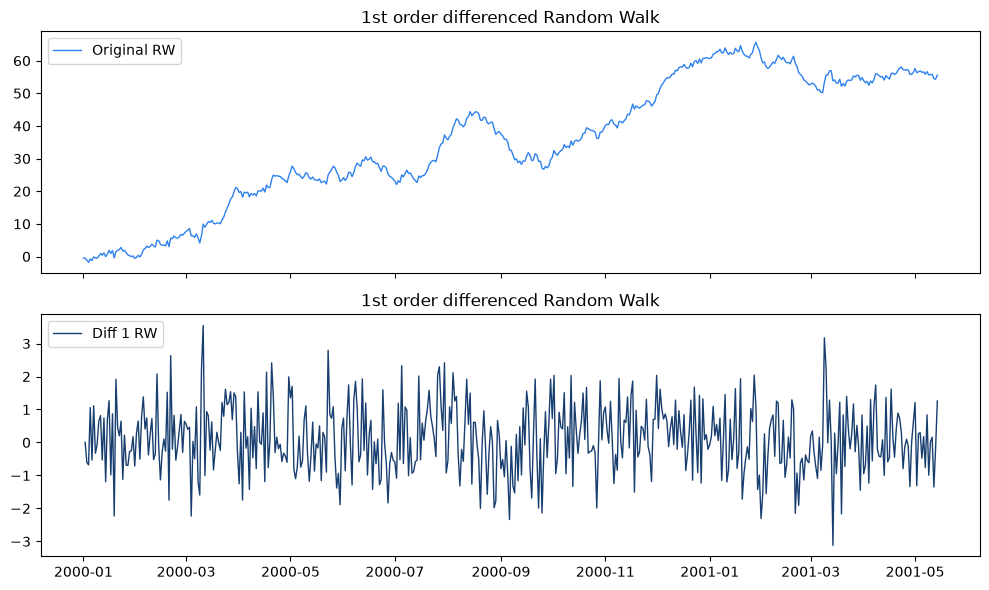

Is the time series stationary?  True


In [23]:
rw_diff = sim['RandomWalk'].diff(1).dropna()   # TODO: first difference of sim['RandomWalk'] (drop the NaN)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(sim['RandomWalk'], color="#2f81ec", lw=1, label='Original RW')
axes[0].set_title('1st order differenced Random Walk')
axes[0].legend(loc='upper left')

axes[1].plot(rw_diff, color="#173e6f", lw=1, label='Diff 1 RW')
axes[1].set_title('1st order differenced Random Walk'); axes[1].legend(loc='upper left')
plt.tight_layout(); plt.show()

# Test the difference
print("Is the time series stationary? ", adf_report(rw_diff, 'diff(RandomWalk)')['stationary?'])

**D.** In a markdown cell, briefly answer: *which series are stationary? What does differencing do to a random walk?*

**D.** *Your answer here:*

...

### **1.2. ACF & PACF**

**A.** Plot the ACF and PACF (40 lags) of the **AR(2)**, **MA(1)** and **random walk**.

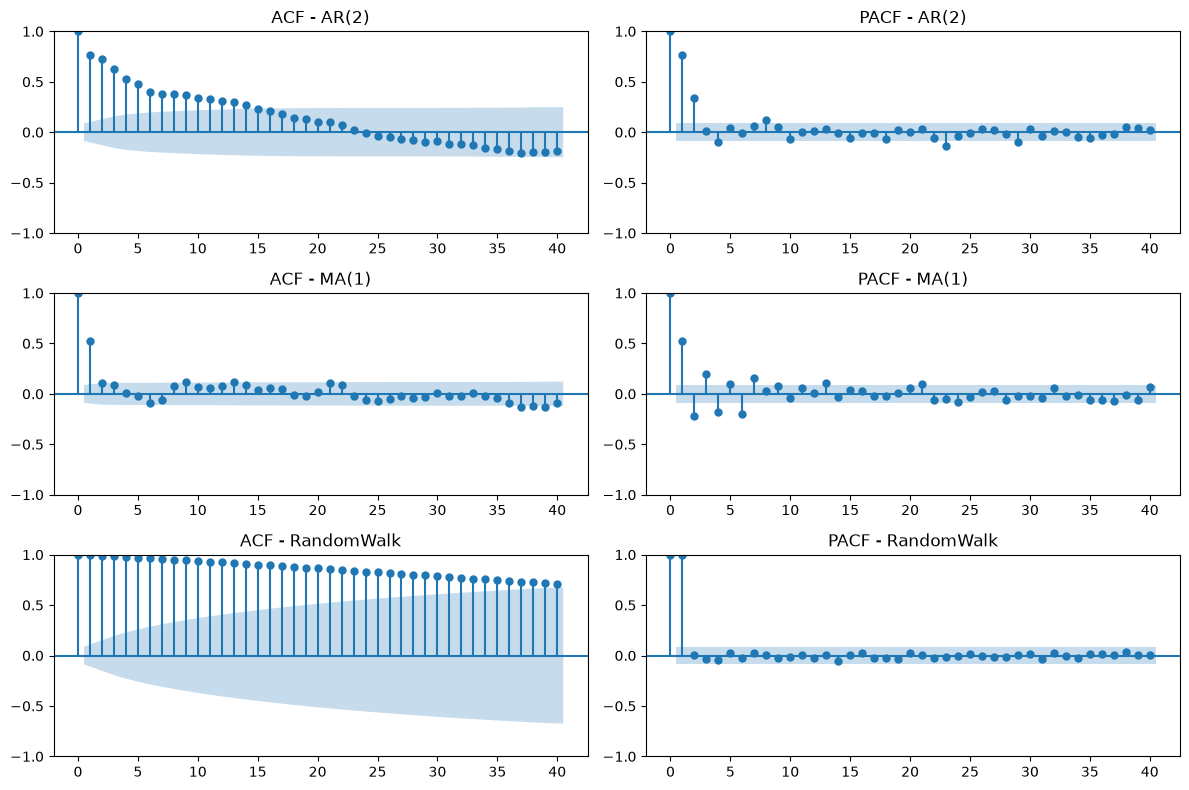

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for i, col in enumerate(sim.columns):
    plot_acf(sim[col], lags=40, ax=axes[i, 0], title=f'ACF - {col}') # TODO: plot_acf(sim[col], lags=40, ax=axes[i, 0], title=f'ACF - {col}')
    plot_pacf(sim[col], lags=40, ax=axes[i, 1], title=f'PACF - {col}', method='ywm') # TODO: plot_pacf(sim[col], lags=40, ax=axes[i, 1], title=f'PACF - {col}', method='ywm')

plt.tight_layout(); plt.show()

**B.** In a markdown cell, fill in the table (cuts off after lag $k$ / decays gradually) and answer: *how do you read $p$ and $q$? Is the random walk ACF consistent with a stationary series?*

| Series | ACF | PACF | Suggested model |
|---|---|---|---|
| AR(2) | ... | ... | p = 2, q = 14 |
| MA(1) | ... | ... | p = 5, q = 1 |

**B.** *Your answer here:*

...

-------

## **2. Real Data: Visualization, Stationarity & Transformation** *(~20 min)*

**Data:** monthly international airline passengers (thousands), 1949-1960 (144 observations).

**Model class of this lab: ARIMA $(p,d,q)$ only** (no seasonal terms). The seasonality is therefore removed **before** modeling, by a **seasonal difference** $X_t-X_{t-12}$ treated as part of the transformation.

### **2.1. Data & Visualization**

Run the cell below to load the data (a simulated series with the same structure is used if there is no internet access).

In [25]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
try:
    air = pd.read_csv(url, parse_dates=['Month'], index_col='Month')
except Exception:                      # fallback if no internet access to GitHub
    rng = np.random.default_rng(SEED)
    t = np.arange(144)
    vals = 110 * np.exp(0.0095 * t) * (1 + 0.22 * np.sin(2 * np.pi * (t - 2) / 12)) * np.exp(rng.normal(0, 0.04, 144))
    air = pd.DataFrame({'Passengers': vals.round()}, index=pd.date_range('1949-01-01', periods=144, freq='MS'))
air.columns = ['Passengers']
air = air.asfreq('MS')
y = air['Passengers']
print(y.shape, y.index.min().date(), '->', y.index.max().date(), '| freq =', y.index.freq)
air.head()

(144,) 1949-01-01 -> 1960-12-01 | freq = <MonthBegin>


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


**A.** Check missing values and plot the series. Then plot the **seasonal profile** (one line per year, x = month) and the **rolling mean / std** (window = 12).

missing: Passengers    0
dtype: int64


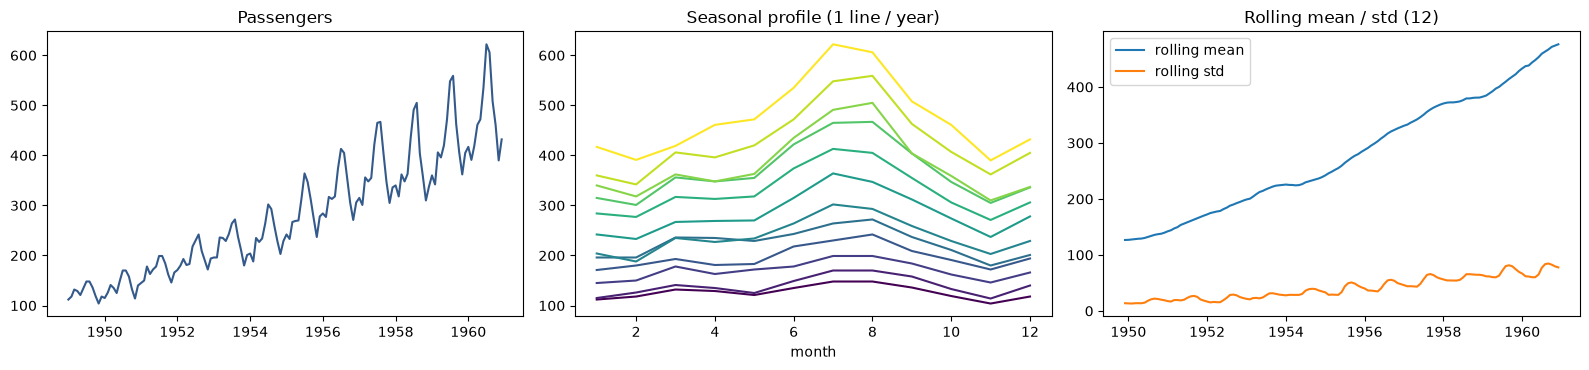

In [27]:
print('missing:', air.isna().sum())   # TODO: number of NaN in y

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(y, color='#345a8b'); axes[0].set_title('Passengers')

pivot = y.to_frame().assign(year=y.index.year, month=y.index.month).pivot(index='month', columns='year', values='Passengers')
pivot.plot(ax=axes[1], legend=False, colormap='viridis'); axes[1].set_title('Seasonal profile (1 line / year)')

roll_mean = y.rolling(12).mean()   # TODO: 12-month rolling mean
roll_std = y.rolling(12).std()    # TODO: 12-month rolling std
axes[2].plot(roll_mean, label='rolling mean'); axes[2].plot(roll_std, label='rolling std')
axes[2].set_title('Rolling mean / std (12)'); axes[2].legend()
plt.tight_layout(); plt.show()

**B.** In a markdown cell, list what you see: *trend? seasonality (period)? does the spread change with the level?*

**B.** *Your answer here:*

...

### **2.2. Stationarity Tests**

**A.** Run **ADF** and **KPSS** on the raw series. KPSS has the **opposite** null: $H_0$: the series is **stationary**.

In [28]:
def kpss_report(x, name='', alpha=0.05):
    stat, pval, *_ = kpss(pd.Series(x).dropna(), regression='c', nlags='auto')
    return {'series': name, 'KPSS stat': stat, 'p-value': pval, 'stationary?': pval > alpha}

adf_raw = adf_report(y, 'Passenger')    # TODO: adf_report on y
kpss_raw = kpss_report(y, 'Passenger')   # TODO: kpss_report on y
display(pd.DataFrame([adf_raw]).round(4)); display(pd.DataFrame([kpss_raw]).round(4))

,series,ADF stat,p-value,stationary?
0,Passenger,0.8154,0.9919,False


,series,KPSS stat,p-value,stationary?
0,Passenger,1.6513,0.01,False


**B.** In a markdown cell, briefly answer: *do both tests agree? Why is it useful to run both?*

**B.** *Your answer here:*

...

### **2.3. Transformation & Differencing**

**A.** Compare variance-stabilizing transformations: `sqrt`, `log`, and `Box-Cox`. A good transformation makes the rolling std **independent of the rolling mean** (correlation $\approx 0$).

> $\lambda$ of Box-Cox is estimated here on the whole series for exploration only. In the modeling part it must be estimated on the **training set only**.

In [ ]:
def spread_vs_level(x, w=12):
    r = pd.Series(x).rolling(w)
    return np.corrcoef(r.mean().dropna(), r.std().dropna())[0, 1]

lam, y_bc = None, None   # TODO: y_bc, lam = stats.boxcox(y)  -> transformed values, lambda
print('Box-Cox lambda =', lam)

transforms = {
    'raw': y,
    'sqrt': None,       # TODO
    'log': None,        # TODO
    'box-cox': pd.Series(y_bc, index=y.index),
}
print(pd.Series({k: spread_vs_level(v) for k, v in transforms.items()}, name='corr(rolling mean, rolling std)').round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (k, v) in zip(axes, transforms.items()):
    ax.plot(v, color='#345a8b'); ax.set_title(k)
plt.tight_layout(); plt.show()

**B.** Using the **log** series `ly`, compare the differencing options below. For each version, run ADF and KPSS and plot it.

- $d=1$: $\Delta X_t$ removes the **trend**.
- $D=1$, lag 12: $X_t-X_{t-12}$ removes the **seasonality** (done *before* ARIMA, since ARIMA has no seasonal term).

In [ ]:
ly = np.log(y)

versions = {
    'log': ly,
    'log, d=1': ly.diff(),
    'log, D=1 (lag 12)': None,         # TODO: seasonal difference ly.diff(12)
    'log, D=1 & d=1': None,            # TODO: both differences
}
tests = pd.DataFrame({k: {'ADF p-value': adf_report(v, k)['p-value'],
                          'KPSS p-value': kpss_report(v, k)['p-value']} for k, v in versions.items()}).T
display(tests.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (k, v) in zip(axes.ravel(), versions.items()):
    ax.plot(v, color='#345a8b', lw=1); ax.set_title(k)
plt.tight_layout(); plt.show()

**C.** In a markdown cell: *which transformation do you keep? After the seasonal difference $w_t=\ln X_t-\ln X_{t-12}$, does the series need one more difference ($d=1$) or not ($d=0$)? Justify with the tests and the plots.*

**C.** *Your answer here:*

...

### **2.4. ACF & PACF**

**A.** Choose `d` (0 or 1, from 2.3.C), build the stationary series `z` (log, seasonal difference at lag 12, then $d$ regular differences) and plot its ACF and PACF (36 lags).

In [ ]:
w = ly.diff(12).dropna()        # log + seasonal difference
d = None                        # TODO: 0 or 1 (from 2.3.C)
z = (w.diff(d) if d > 0 else w).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
# TODO: plot_acf(z, lags=36, ax=axes[0])
# TODO: plot_pacf(z, lags=36, ax=axes[1], method='ywm')
plt.tight_layout(); plt.show()

**B.** In a markdown cell, read $p$ (PACF) and $q$ (ACF) from the **first lags** ($1,2,3$). Any remaining spike at lag 12 cannot be captured by a non-seasonal ARIMA with small order: just note it.

Write your candidate model as $\text{ARIMA}(p,d,q)$ on $w_t$.

**B.** *Your answer here:*

...

-------

## **3. Modeling, Tuning & Evaluation** *(~25 min)*

**Rule:** the test set is **never** used to fit, to choose the transformation parameters, or to tune. All tuning is done with a **time-ordered** CV **inside the training set**.

### **3.1. Chronological Split**

**A.** Keep the **last 24 months** as the test set (no shuffling). Work on the log scale for fitting, but evaluate on the **original scale**.

In [ ]:
h, s = 24, 12
train, test = None, None          # TODO: log series, first part / last h months
y_train, y_test = None, None      # TODO: original-scale series, same split

print(len(train), len(test), '|', train.index[-1].date(), '|', test.index[0].date())

**B.** In a markdown cell, briefly answer: *why is `train_test_split(shuffle=True)` wrong here? If we used Box-Cox, on which data should $\lambda$ be estimated?*

**B.** *Your answer here:*

...

### **3.2. Metrics & Baselines**

**A.** Complete `evaluate` (RMSE, MAPE, RMSE/mean(y)) and build two baselines on the test set:

- **Naive**: repeat the last training value.
- **Seasonal naive**: repeat the last 12 training values (2 times to cover 24 months).

In [ ]:
def evaluate(y_true, y_pred):
    rmse = None   # TODO: root_mean_squared_error
    return {'RMSE': rmse,
            'MAPE': None,            # TODO: mean_absolute_percentage_error
            'RMSE/mean(y)': None}    # TODO

naive = np.full(h, y_train.iloc[-1])
snaive = None   # TODO: np.tile(last 12 training values, h // 12)

rows = {'Naive': {'AIC': np.nan, 'BIC': np.nan, **evaluate(y_test, naive)},
        'Seasonal naive': {'AIC': np.nan, 'BIC': np.nan, **evaluate(y_test, snaive)}}
forecasts = {'Seasonal naive': pd.Series(snaive, index=y_test.index)}
pd.DataFrame(rows).T.round(3)

### **3.3. Fit & Compare ARIMA Models**

**A.** The helper `forecast_original` runs the full pipeline for one candidate:

1. log series $\to$ seasonal difference at lag `s` (skipped if `s=None`) $=w_t$;
2. fit `ARIMA(w, order=(p,d,q))` and forecast `steps` ahead;
3. **invert** the pipeline: $\ln\widehat X_{t}=\ln X_{t-12}+\widehat w_t$ (recursively beyond 12 steps), then `np.exp`.

Complete the fit and the forecast lines.

In [ ]:
def forecast_original(order, ly_tr, steps, s=12):
    # 1) log + seasonal difference
    w_tr = ly_tr if s is None else ly_tr.diff(s).iloc[s:]
    # 2) ARIMA on w_tr
    res = None      # TODO: ARIMA(w_tr, order=order).fit()
    w_fc = None     # TODO: res.forecast(steps=steps).to_numpy()
    # 3) invert
    if s is None:
        return res, np.exp(w_fc)
    hist = list(ly_tr.iloc[-s:])
    for k in range(steps):
        hist.append(hist[k] + w_fc[k])          # ln X_{T+k+1} = ln X_{T+k+1-s} + w_{T+k+1}
    return res, np.exp(np.array(hist[s:]))

**B.** Compare three ARIMA models on the test set:

- `ARIMA(1,1,1)` on the **log** series only (no seasonal difference, `s=None`).
- **Your ARIMA** from Section 2.4 on $w_t$ (`s=12`).
- `ARIMA(2,1,2)` on $w_t$ (`s=12`): larger model.

In [ ]:
specs = {
    'ARIMA(1,1,1) on log': ((1, 1, 1), None),
    'ARIMA (mine) on log+D12': (None, 12),          # TODO: replace None by your (p, d, q) from Section 2.4
    'ARIMA(2,1,2) on log+D12': ((2, 1, 2), 12),
}
fits = {}
for name, (order, s_) in specs.items():
    res, fc = None, None   # TODO: forecast_original(order, train, h, s=s_)
    fc = pd.Series(fc, index=y_test.index)
    fits[name], forecasts[name] = res, fc
    rows[name] = {'AIC': res.aic, 'BIC': res.bic, **evaluate(y_test, fc)}

pd.DataFrame(rows).T.round(3)

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
y.iloc[-60:].plot(ax=ax, color='k', lw=1.5, label='Observed')
for name, fc in forecasts.items():
    fc.plot(ax=ax, label=name)
ax.axvline(y_test.index[0], color='gray', ls='--'); ax.legend(); plt.show()

**C.** In a markdown cell, briefly answer:

  (i) Which model is best on the test set? Does it beat the seasonal naive baseline? Why does `ARIMA(1,1,1)` on the log series fail?

  (ii) Why can **AIC/BIC not** be used to compare `ARIMA(1,1,1)` (log) with the two other models?

**C.** *Your answer here:*

(i) ...

(ii) ...

### **3.4. Hyperparameter Tuning with Time Series CV**

**A.** Complete `cv_rmse`: for each fold of `TimeSeriesSplit` (**expanding window**: train on the past, validate on the next 12 months), fit the model with `forecast_original`, forecast the validation block (already back-transformed), and compute the RMSE on the original scale. Return the mean over folds.

```
fold 1: [train.......][val]
fold 2: [train..........][val]
fold 3: [train.............][val]
fold 4: [train.................][val]
```

In [ ]:
tscv = TimeSeriesSplit(n_splits=4, test_size=12)     # applied on `train` only

def cv_rmse(order, series, cv, s=12):
    scores = []
    for tr_idx, va_idx in cv.split(series):
        ly_tr, ly_va = series.iloc[:va_idx[0]], series.iloc[va_idx]     # everything before the validation block
        try:
            _, pred = None, None   # TODO: forecast_original(order, ly_tr, len(ly_va), s=s)
            scores.append(None)    # TODO: RMSE between np.exp(ly_va) and pred
        except Exception:
            scores.append(np.nan)
    return np.nanmean(scores)

# sanity check on one model
print(cv_rmse((0, 1, 1), train, tscv))

**B.** Grid search over $p\in\{0,1,2\}$, $d\in\{0,1\}$, $q\in\{0,1,2\}$ on $w_t$ (18 models $\times$ 4 folds, takes ~1-2 min). Show the 10 best models.

In [ ]:
grid = list(itertools.product([0, 1, 2], [0, 1], [0, 1, 2]))    # p, d, q

t0 = time.time()
cv_rows = []
for p, d_, q in grid:
    score = None   # TODO: cv_rmse((p, d_, q), train, tscv)
    cv_rows.append({'p': p, 'd': d_, 'q': q, 'CV RMSE': score})
cv_tab = pd.DataFrame(cv_rows).sort_values('CV RMSE').reset_index(drop=True)
print(f'{time.time() - t0:.0f}s')
cv_tab.head(10).round(3)

**C.** In a markdown cell, briefly answer: *why do we tune on CV folds from `train` and not on `test`? Is the best CV model close to your ARIMA from Section 2.4? Can CV compare different $d$ while AIC cannot?*

**C.** *Your answer here:*

...

### **3.5. Final Evaluation (test set, used once)**

**A.** Refit the best CV model on the **whole training set**, forecast the test set and add it to the comparison table. Plot the forecasts.

In [ ]:
best = cv_tab.iloc[0]
order_b = (int(best['p']), int(best['d']), int(best['q']))
name_b = f'CV-best ARIMA{order_b} on log+D12'

res_b, fc_b = None, None   # TODO: forecast_original(order_b, train, h, s=12)
fc_b = pd.Series(fc_b, index=y_test.index)
fits[name_b], forecasts[name_b] = res_b, fc_b
rows[name_b] = {'AIC': res_b.aic, 'BIC': res_b.bic, **evaluate(y_test, fc_b)}

display(pd.DataFrame(rows).T.sort_values('RMSE').round(3))

fig, ax = plt.subplots(figsize=(11, 4))
y.iloc[-60:].plot(ax=ax, color='k', lw=1.5, label='Observed')
for name, fc in forecasts.items():
    fc.plot(ax=ax, label=name)
ax.axvline(y_test.index[0], color='gray', ls='--'); ax.legend(); plt.show()

**B.** In a markdown cell, briefly answer:

  (i) Which model do you report? Compare the CV RMSE of the best model with its test RMSE.

  (ii) Name two ways a time series evaluation can leak future information.

**B.** *Your answer here:*

(i) ...

(ii) ...

-------

## **4. Going Further** *(Homework)*

The sections below are for you to complete **after class**.

### **4.1. Residual Diagnostics**

**A.** For the CV-best model, plot the residual diagnostics and run the **Ljung-Box** test ($H_0$: no autocorrelation in the residuals) at lags 12 and 24. Drop the first $d$ residuals (not meaningful).

In [ ]:
resid = res_b.resid.iloc[order_b[1]:]

fig = res_b.plot_diagnostics(figsize=(11, 7)); plt.show()
lb = None   # TODO: acorr_ljungbox(resid, lags=[12, 24])
lb

**B.** In a markdown cell: *are the residuals consistent with white noise? What would you change if not?*

**B.** *Your answer here:*

...

### **4.2. Prediction Intervals**

**A.** Get the 95% forecast interval of the CV-best model for the **first 12 months** of the test set. For these steps the inversion is exact: $\ln X_{T+k}=\ln X_{T+k-12}+w_{T+k}$, so both bounds are `np.exp(base + bound_of_w)` with `base = train.iloc[-12:]`.

Plot it and compute the **empirical coverage** on the test set (proportion of the 12 test points inside the interval).

In [ ]:
k = 12
base = train.iloc[-12:].to_numpy()
sf = None   # TODO: res_b.get_forecast(steps=k).summary_frame(alpha=0.05)
lower = np.exp(base + sf['mean_ci_lower'].to_numpy())
upper = np.exp(base + sf['mean_ci_upper'].to_numpy())

obs = y_test.iloc[:k]
coverage = None   # TODO: proportion of obs within [lower, upper]
print(f'coverage = {coverage:.1%}')

fig, ax = plt.subplots(figsize=(11, 4))
y.iloc[-36:].plot(ax=ax, color='k', label='Observed')
ax.plot(obs.index, fc_b.iloc[:k], color='red', label='Forecast')
ax.fill_between(obs.index, lower, upper, color='red', alpha=.2, label='95% PI')
ax.legend(); plt.show()

### **4.3. Full Workflow on a New Series: PM2.5 in Phnom Penh**

Hourly PM2.5 (Open-Meteo API, last 60 days). Apply the **same workflow** with a **non-seasonal** `ARIMA(p,d,q)`, as in the lecture.

In [ ]:
import requests
r = requests.get('https://air-quality-api.open-meteo.com/v1/air-quality',
                 params={'latitude': 11.5564, 'longitude': 104.9282, 'hourly': 'pm2_5',
                         'timezone': 'Asia/Bangkok', 'past_days': 60, 'forecast_days': 0}).json()
pm = pd.DataFrame(r['hourly'])
pm['time'] = pd.to_datetime(pm['time'])
pm = pm.set_index('time')['pm2_5'].dropna()
print(pm.shape)
pm.head()

**A.** Do the following (add cells below):

1. Plot the series and its **daily pattern** (mean PM2.5 by hour of the day).
2. Test stationarity (ADF + KPSS) on the raw and the differenced series.
3. Compare `sqrt` / `log1p` with `spread_vs_level` (window 24); keep one.
4. Plot ACF/PACF (lags up to 48) and propose $(p,1,q)$.
5. Split the **last 10%** as test; tune $(p, q)$ with `TimeSeriesSplit` on the training part only.
6. Compare the tuned ARIMA with the **naive** and **seasonal naive (lag 24)** baselines on the test set (RMSE, MAPE).
7. Does ARIMA beat the baselines for long horizons? Explain.

In [ ]:
# your code here

**A.** *Your answer here:*

...

-------

## **Wrap-up**

In this lab you:

- **Visualized** series, tested **stationarity** (ADF / KPSS), and read orders from **ACF / PACF** (Sections 1-2).
- Applied **transformations** (log, Box-Cox) and **differencing** (seasonal lag 12 and regular $d$) to make a series stationary (Section 2).
- Split the data **chronologically**, built **baselines**, fitted **ARIMA$(p,d,q)$** models, inverted the transformation, and **tuned** $(p,d,q)$ with **expanding-window CV** inside the training set (Section 3).
- *(At home)* Checked **residuals**, built **prediction intervals**, and repeated the workflow on a real PM2.5 series (Section 4).

The core idea: **make it stationary, identify with ACF/PACF, tune with time-ordered CV on the training set only, and report the test error once against a naive baseline.**